# Chapter 4: Training Models — Test Field (Insurance Dataset)

This is an independent playground to test Chapter 4 concepts (Linear Regression, Gradient Descent, Polynomial Regression, Regularization) on real-world medical cost data.

## 1. Loading the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset directly from raw online link
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

# Display the first few rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Output meaning:** The dataset contains 1,338 records with features (`age`, `sex`, `bmi`, `children`, `smoker`, `region`) and the target variable `charges` (medical expenses in USD).

In [2]:
# Check structure and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


**Output meaning:** 1,338 entries with zero missing values. We have both numerical and categorical features.

---
## 2. Testing Linear Regression on Real Data: `age` vs `charges`

Let's test Chapter 4's Linear Regression formulas to model how `age` affects `charges`.

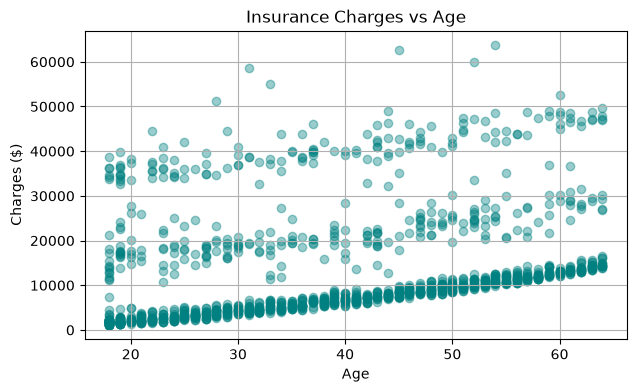

In [3]:
# Visualize the relationship
plt.figure(figsize=(7, 4))
plt.scatter(df["age"], df["charges"], alpha=0.4, color="teal")
plt.xlabel("Age")
plt.ylabel("Charges ($)")
plt.title("Insurance Charges vs Age")
plt.grid(True)
plt.show()

**Output meaning:** There is a clear upward baseline trend: older patients incur higher medical charges on average.

### Testing The Normal Equation: $\hat{\mathbf{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$

In [4]:
X = df[["age"]].values
y = df[["charges"]].values

# Add x0 = 1 column for the bias term
X_b = np.c_[np.ones((len(X), 1)), X]

# Compute theta using the Normal Equation
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("Normal Equation Intercept (theta_0):", theta_best[0][0])
print("Normal Equation Slope (theta_1):    ", theta_best[1][0])

Normal Equation Intercept (theta_0): 3165.8850060630275
Normal Equation Slope (theta_1):     257.7226186668953


**Output meaning:**
- **Intercept ($\theta_0 \approx 3,165.89$)**: Base estimated charge at age 0.
- **Slope ($\theta_1 \approx 257.72$)**: For every 1-year increase in age, insurance charges increase by ~\$257.72 on average.

### Visualizing the Model Fit

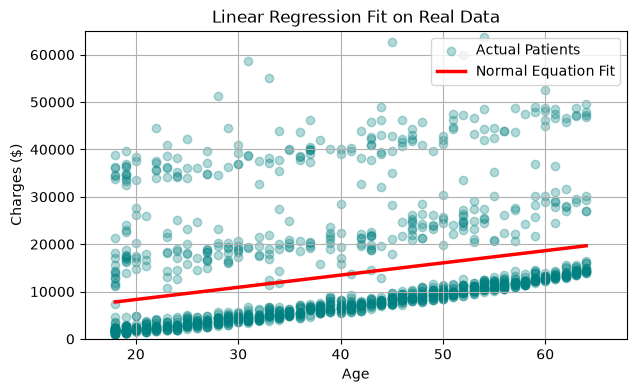

In [5]:
# Predict on min and max ages: 18 and 64
X_new = np.array([[18], [64]])
X_new_b = np.c_[np.ones((2, 1)), X_new]
y_predict = X_new_b @ theta_best

plt.figure(figsize=(7, 4))
plt.scatter(df["age"], df["charges"], alpha=0.3, color="teal", label="Actual Patients")
plt.plot(X_new, y_predict, "r-", linewidth=2.5, label="Normal Equation Fit")
plt.xlabel("Age")
plt.ylabel("Charges ($)")
plt.title("Linear Regression Fit on Real Data")
plt.axis([15, 68, 0, 65000])
plt.grid(True)
plt.legend()
plt.show()

**Output meaning:** The red regression line captures the general upward trend of baseline costs across ages.

### Verifying with Scikit-Learn `LinearRegression`

In [6]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

print("Scikit-Learn Intercept:", lin_reg.intercept_[0])
print("Scikit-Learn Slope:    ", lin_reg.coef_[0][0])

Scikit-Learn Intercept: 3165.8850060630284
Scikit-Learn Slope:     257.72261866689547


**Output meaning:** Exactly matches the Normal Equation parameters down to every decimal, confirming Scikit-Learn's underlying linear algebra on real data.